## Generating and testing a hypothesis

Purpose: We want to assess the correlation of structure (e.g. lipophilicity) of some molecules with their inhibitory activity for Acetylcholinesterase (AChE). 

We have already seen that the correlation doesn't seem to be too strong, but is it statistically significant? Hence our hypothesis is still: "High lipohilicity (XlogP) leads to higher potency (pchembl_value)".

Import dependencies and load the combined dataset for assessing our "quantitative structure-activity relationship" (QSAR).

In [2]:
import pandas as pd

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load both datasets
df = pd.read_csv("C:\\Users\\bharg\\Shriji\\UZH CHE 101 and CHE 103\\UZH CHE 103 ADVANCED DATA SCIENCE\\ChemicalDataScience103\\lectures\\session09\\materials\\cleaned_data.csv")
df.head()


,canonical_smiles,pchembl_value,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount
0,C(=C/C1CCN(Cc2ccccc2)CC1)\c1noc2ccccc12,6.68,9901561,318.4,4.5,29.3,0,3,4
1,C/C=C1\[C@H]2C=C(C)C[C@]1(NC1OCC3=C4CC(C)(C)C[...,6.96,118715261,492.6,1.2,90.8,4,5,2
2,C=CC(=O)N1C/C(=C\c2ccc(C)cc2)C(=O)/C(=C/c2ccc(...,4.74,24796898,357.4,4.4,37.4,0,2,3
3,C=CC(=O)N1C/C(=C\c2ccc(Cl)cc2Cl)C(=O)/C(=C/c2c...,4.80,71720637,467.2,6.2,37.4,0,2,3
4,C=CC[N+](C)(C)c1ccc(CCC(=O)CCc2ccc([N+](C)(C)C...,8.10,1338,406.6,4.8,17.1,0,1,12


In [5]:
import os
print(os.getcwd())

c:\Users\bharg\Shriji\UZH CHE 101 and CHE 103\UZH CHE 103 ADVANCED DATA SCIENCE\ChemicalDataScience103\lectures\session09\materials


In [ ]:
df2= pd.read_csv("./cleaned_data.csv")
df2.head()

,canonical_smiles,pchembl_value,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount
0,C(=C/C1CCN(Cc2ccccc2)CC1)\c1noc2ccccc12,6.68,9901561,318.4,4.5,29.3,0,3,4
1,C/C=C1\[C@H]2C=C(C)C[C@]1(NC1OCC3=C4CC(C)(C)C[...,6.96,118715261,492.6,1.2,90.8,4,5,2
2,C=CC(=O)N1C/C(=C\c2ccc(C)cc2)C(=O)/C(=C/c2ccc(...,4.74,24796898,357.4,4.4,37.4,0,2,3
3,C=CC(=O)N1C/C(=C\c2ccc(Cl)cc2Cl)C(=O)/C(=C/c2c...,4.80,71720637,467.2,6.2,37.4,0,2,3
4,C=CC[N+](C)(C)c1ccc(CCC(=O)CCc2ccc([N+](C)(C)C...,8.10,1338,406.6,4.8,17.1,0,1,12


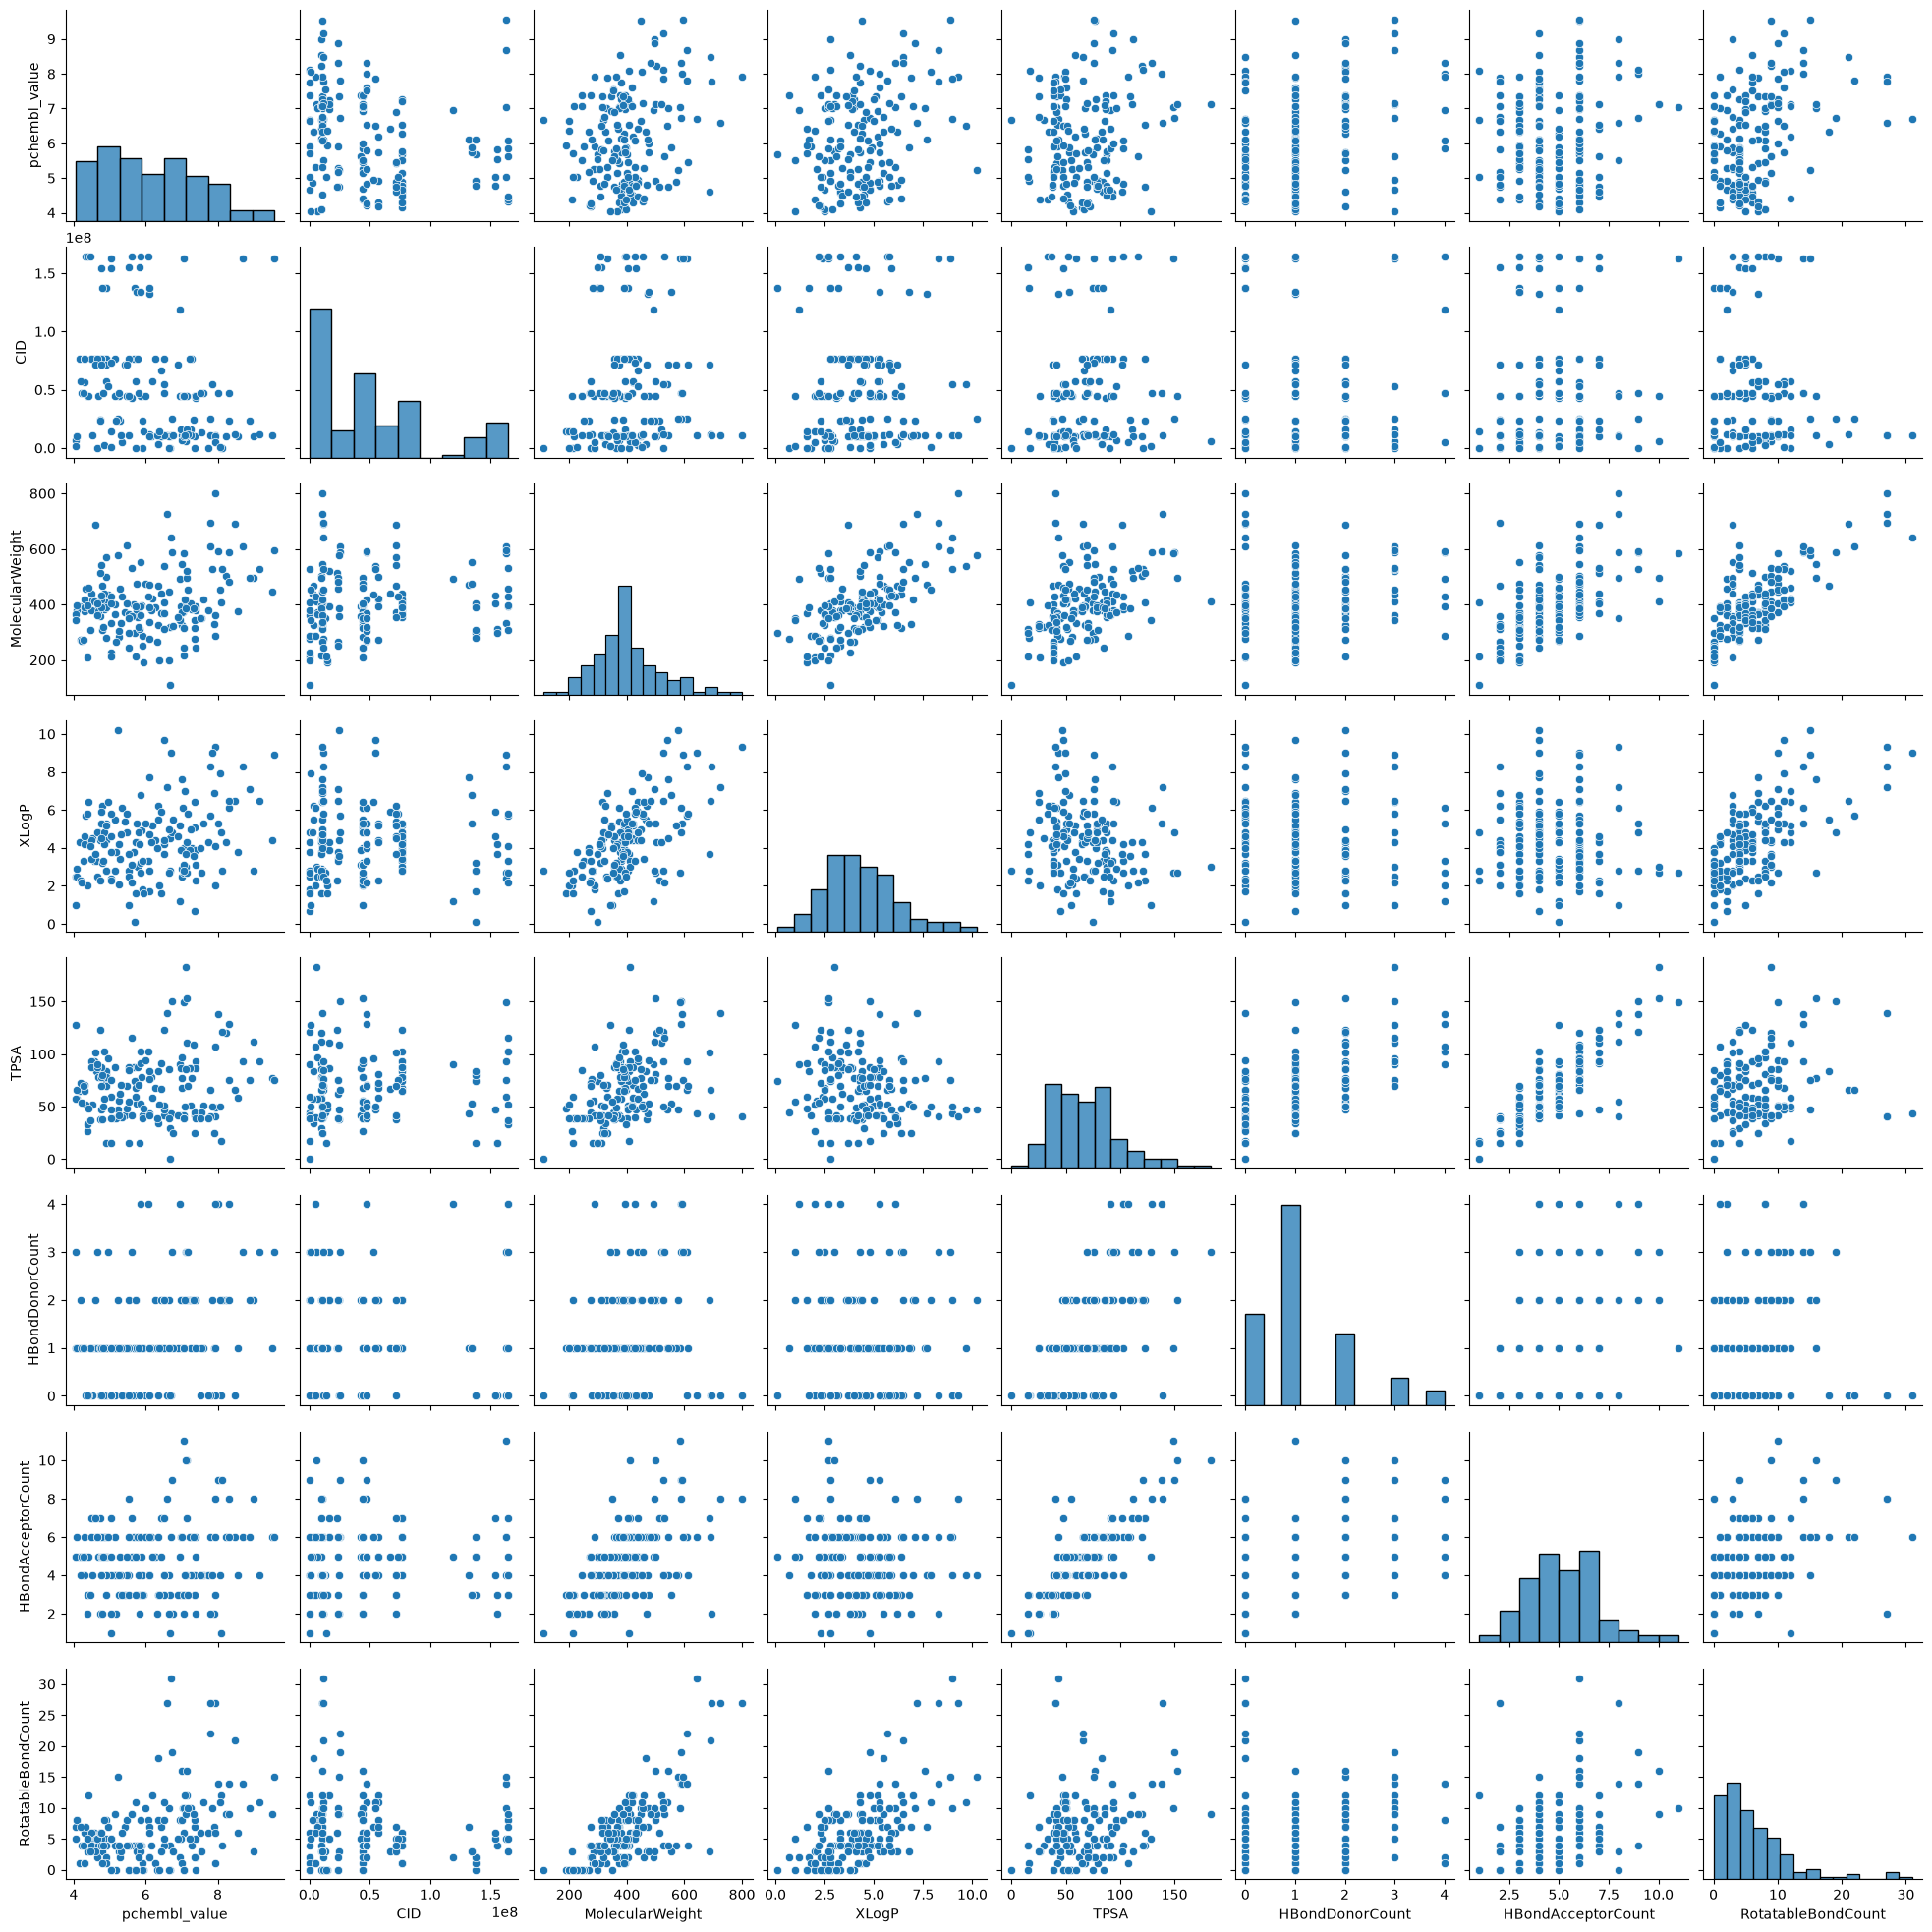

In [2]:
sns.pairplot(data=df)
plt.show()

Produce a scatterplot of the columns "XLogP" and "pchembl_value".

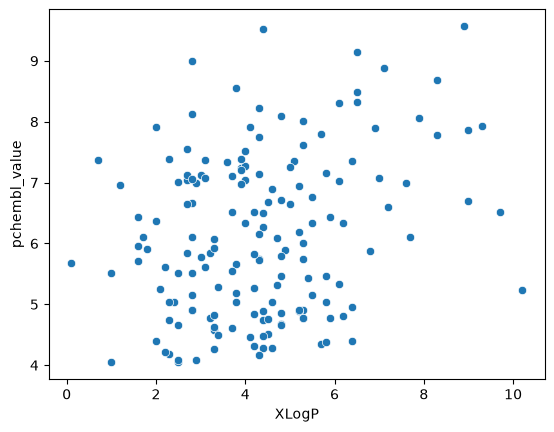

In [4]:
sns.scatterplot(x=df['XLogP'], y=df['pchembl_value'])
plt.show()

To test our hypothesis, we will have a look at highly lipophilic molecules and compare them to the rest. The null-hypothesis is that for both groups, the mean will be the same (mean_low = mean_high).

First, let's create a new column "high_logp" with the condition to XLogP > 3 to start with.

In [5]:
df['high_logP']= df['XLogP']>3

In [6]:
df

,canonical_smiles,pchembl_value,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,high_logP
0,C(=C/C1CCN(Cc2ccccc2)CC1)\c1noc2ccccc12,6.68,9901561,318.40,4.5,29.3,0,3,4,True
1,C/C=C1\[C@H]2C=C(C)C[C@]1(NC1OCC3=C4CC(C)(C)C[...,6.96,118715261,492.60,1.2,90.8,4,5,2,False
2,C=CC(=O)N1C/C(=C\c2ccc(C)cc2)C(=O)/C(=C/c2ccc(...,4.74,24796898,357.40,4.4,37.4,0,2,3,True
3,C=CC(=O)N1C/C(=C\c2ccc(Cl)cc2Cl)C(=O)/C(=C/c2c...,4.80,71720637,467.20,6.2,37.4,0,2,3,True
4,C=CC[N+](C)(C)c1ccc(CCC(=O)CCc2ccc([N+](C)(C)C...,8.10,1338,406.60,4.8,17.1,0,1,12,True
...,...,...,...,...,...,...,...,...,...,...
159,c1ccc2c(NCCCCCCCCNc3c4c(nc5ccccc35)CCCC4)ccnc2c1,8.06,656986,452.60,7.9,49.8,2,4,11,True
160,c1ccc2c(c1)CN1CCCCCCC1=N2,5.04,14318563,214.31,2.3,15.6,0,1,0,False
161,c1ccc2c(c1)Cc1c-2nc2ccccc2c1NCCCCCCCNc1c2c(nc3...,7.86,54577393,526.70,9.0,49.8,2,4,10,True
162,c1cnc2nc3c(c(NCCCCCCCNc4c5c(nc6ncccc46)CCCC5)c...,8.89,23644779,494.70,7.1,75.6,2,6,10,True


Now, calculate the means for all low_logp and high_logp molecules. For this, use the "high_logp" column to create two groups. Compare their size, mean and their variance.

In [9]:
group_high=df[df['high_logP']]['pchembl_value']
group_low=df[~df['high_logP']]['pchembl_value']

print("shape of group_high", group_high.shape[0])
print("shape of group_low", group_low.shape[0])
print("shape of group_high", group_high.mean())
print("shape of group_low", group_low.mean())
print("shape of group_high", group_high.var())
print("shape of group_low", group_low.var())


shape of group_high 120
shape of group_low 44
shape of group_high 6.208875000000001
shape of group_low 5.927954545454545
shape of group_high 1.8307447321428572
shape of group_low 1.5346364164904862


Now, run a two-sample t-test to assess our null-hypothesis ("the means of the two groups are equal"). If the p_value is lower than 0.05, we can reject the null-hypothesis and our alternative hypothesis is true, i.e. there is a significant difference between the two means (which tells us that the higher lipophilicity leads to increased activity). Try different values for the lipophilicity threshold.

In [10]:
# t-test

t_value, p_value = stats.ttest_ind(group_high, group_low, equal_var=False, nan_policy="omit")
print(f"t_value = {t_value:.2f}, p_value = {p_value:.6f}")

t_value = 1.25, p_value = 0.213130


Interpret the results!